# 05 — What makes a chamber easy or hard to find?

*Weeks 6–7*

Choose **two** studies. Each study changes one parameter while all other baseline parameters stay fixed. Use **expected significance** for clean, reproducible comparisons unless your mentor asks you to study statistical fluctuations explicitly.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## Helper: expected significance for a fixed exposure

Studies A–C follow the ray through the chamber centre so the result does not jump
when the centre falls between angular pixels. Study D uses the full grid because
bin size is what we are changing.

In [2]:
def make_target(radius=cfg.VOID_RADIUS_M, centre=cfg.VOID_CENTRE_M,
                density=cfg.ROCK_DENSITY_G_CM3, has_void=True):
    return mg.Pyramid(
        base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
        density=density, void_centre=centre, void_radius=radius,
        has_void=has_void,
    )


def on_axis_stats(target, detector, days):
    # follow the ray from the detector through the centre of the chamber
    direction = np.asarray(target.void_centre) - detector
    direction = direction / np.linalg.norm(direction)
    theta = mg.zenith_from_direction(direction)
    opacity_void = mg.trace_one_ray(target, detector, direction, step=cfg.RAY_STEP_M)
    opacity_solid = mg.trace_one_ray(target.without_void(), detector, direction, step=cfg.RAY_STEP_M)

    # keep the detector area and pixel size the same for a fair comparison
    pixel_sr = mg.pixel_solid_angle(np.radians(cfg.STEP_DEG))
    exposure = cfg.DETECTOR_AREA_M2 * pixel_sr * days * mg.DAY
    mu_void = mg.transmitted_flux(opacity_void, theta) * exposure
    mu_solid = mg.transmitted_flux(opacity_solid, theta) * exposure
    S = float(mg.expected_significance(mu_void, mu_solid))
    return S, days * (5 / S)**2 if S > 0 else np.inf


target0 = make_target()
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)
days = 30.0

## Study A — How small a chamber can we find?

Vary `void_radius` from 4 m to 20 m at fixed depth and 30 days. Before running, write down your prediction. Plot **expected** peak significance against radius and explain the trend. The chamber is defined by radius, so a “10 m chamber” means 10 m radius (20 m diameter).


Radius: 4 m, S: 2.262 sigma, 5 sigma exposure: 146.57 days
Radius: 6 m, S: 3.562 sigma, 5 sigma exposure: 59.11 days
Radius: 8 m, S: 4.995 sigma, 5 sigma exposure: 30.07 days
Radius: 10 m, S: 6.578 sigma, 5 sigma exposure: 17.33 days
Radius: 12 m, S: 8.334 sigma, 5 sigma exposure: 10.80 days
Radius: 14 m, S: 10.289 sigma, 5 sigma exposure: 7.09 days
Radius: 16 m, S: 12.472 sigma, 5 sigma exposure: 4.82 days
Radius: 18 m, S: 16.540 sigma, 5 sigma exposure: 2.74 days
Radius: 20 m, S: 19.435 sigma, 5 sigma exposure: 1.99 days


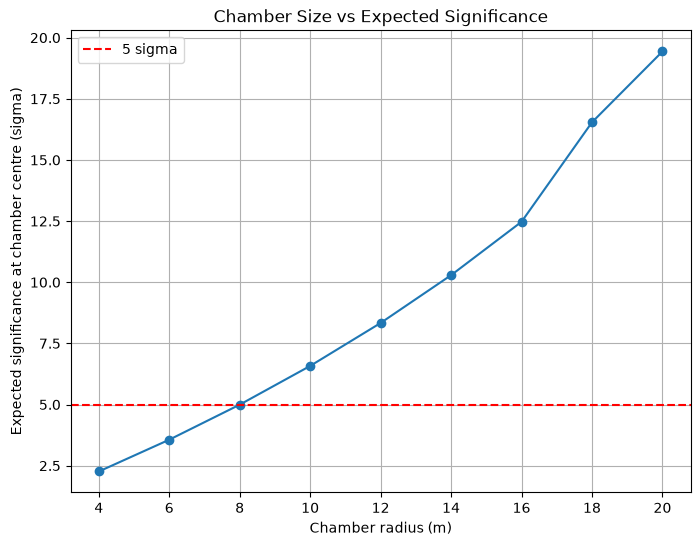

In [3]:
# How chamber size affects significance 

radii = np.arange(4, 21, 2)
significances = []
T5_A = []

for radius in radii:

    # make a pyramid with this chamber size
    test_target = make_target(radius=float(radius))

    # check the signal along the ray through the chamber centre
    S, t5 = on_axis_stats(test_target, detector, days)

    significances.append(S)

    T5_A.append(t5)
    print(f"Radius: {radius} m, S: {S:.3f} sigma, 5 sigma exposure: {t5:.2f} days")

plt.figure(figsize=(8, 6))

plt.plot(radii, significances, marker="o")

# our 5 sigma target
plt.axhline(5, color="red", linestyle="--",
            label="5 sigma")

plt.xlabel("Chamber radius (m)")
plt.ylabel("Expected significance at chamber centre (sigma)")
plt.title("Chamber Size vs Expected Significance")

plt.legend()
plt.grid(True)

plt.show()

**Conclusion:** A bigger chamber leaves a longer stretch of air along the ray,
so more muons make it through. The 8 m chamber is just below 5σ at 30 days
(4.995σ), so 10 m is the first tested radius that actually crosses it.

## Study B — Does depth matter?

Move the chamber centre from 55 to 110 m above the base while keeping the
radius, detector position and exposure fixed. At lower heights the centre
ray can fall outside the detector's viewing angles.

Height: 55 m, S: 6.974 sigma, 5 sigma exposure: 15.42 days
Height: 60 m, S: 6.853 sigma, 5 sigma exposure: 15.97 days
Height: 65 m, S: 6.702 sigma, 5 sigma exposure: 16.70 days
Height: 70 m, S: 6.578 sigma, 5 sigma exposure: 17.33 days
Height: 75 m, S: 6.429 sigma, 5 sigma exposure: 18.15 days
Height: 80 m, S: 6.283 sigma, 5 sigma exposure: 19.00 days
Height: 85 m, S: 6.140 sigma, 5 sigma exposure: 19.89 days
Height: 90 m, S: 6.024 sigma, 5 sigma exposure: 20.67 days
Height: 95 m, S: 5.888 sigma, 5 sigma exposure: 21.63 days
Height: 100 m, S: 6.722 sigma, 5 sigma exposure: 16.60 days
Height: 105 m, S: 6.605 sigma, 5 sigma exposure: 17.19 days
Height: 110 m, S: 6.490 sigma, 5 sigma exposure: 17.81 days


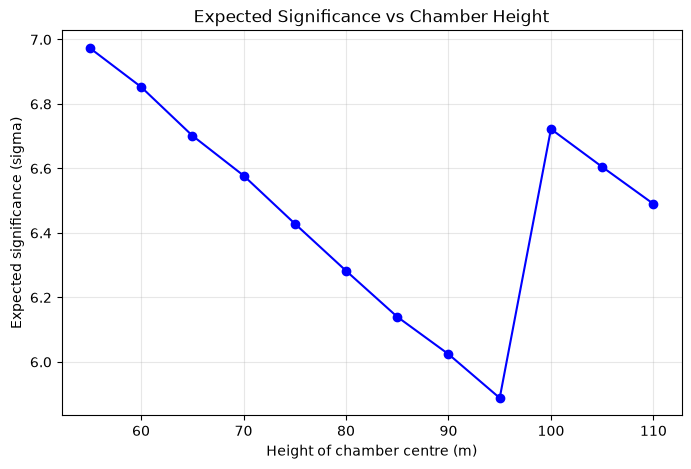

In [4]:
depths = np.arange(55, 111, 5)
S_B = []
T5_B = []

# move the chamber vertically and leave the detector where it was
for z in depths:
    test_target = make_target(centre=(0, 0, float(z)))
    S, t5 = on_axis_stats(test_target, detector, days)
    S_B.append(S)
    T5_B.append(t5)
    print(f"Height: {z} m, S: {S:.3f} sigma, 5 sigma exposure: {t5:.2f} days")

plt.figure(figsize=(8, 5))
plt.plot(depths, S_B, marker="o", color="blue")
plt.xlabel("Height of chamber centre (m)")
plt.ylabel("Expected significance (sigma)")
plt.title("Expected Significance vs Chamber Height")
plt.grid(alpha=0.3)
plt.show()

**Study B — Conclusion:** Changing the height changes both the zenith
angle and how much rock is in the way. In this scan the weakest signal
was at 95 m. It picks up again as the chamber gets closer to the apex.

## Study C — Where should the detector stand?

Keep the chamber fixed and move the detector position. Compare expected significance or expected exposure time, while making sure every detector position still has the chamber in its field of view. This is a simplified placement study, not a complete detector-engineering optimisation.


y = -55 m: 21.73 days
y = -50 m: 20.02 days
y = -45 m: 18.56 days
y = -40 m: 17.33 days
y = -35 m: 16.58 days
y = -30 m: 15.98 days
y = -25 m: 15.94 days
y = -20 m: 16.18 days
y = -15 m: 16.98 days
x = -30 m: 17.06 days
x = -20 m: 19.76 days
x = -10 m: 17.92 days
x =   0 m: 17.33 days
x =  10 m: 17.92 days
x =  20 m: 19.76 days
x =  30 m: 17.06 days


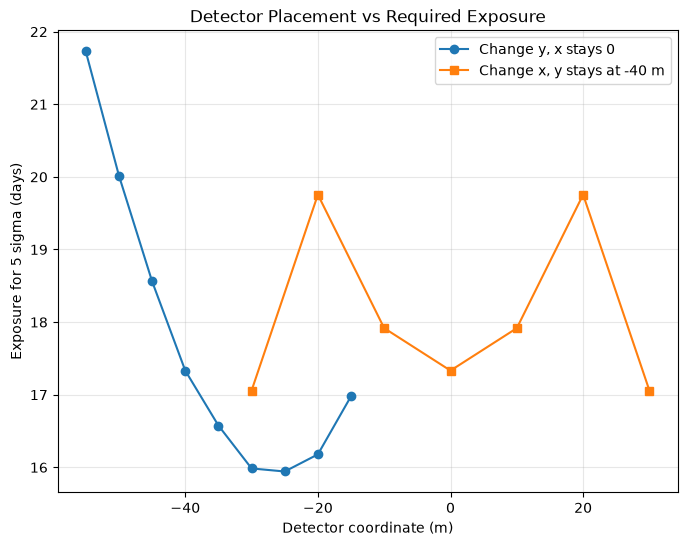

Best tested y position: -25 m (15.94 days)


In [5]:
# first move toward the centre, then slide sideways at the baseline y
distances = np.arange(-55, -14, 5)
lateral = np.arange(-30, 31, 10)
T5_C = []
T5_Cx = []

for y in distances:
    position = np.array([0, y, detector[2]], dtype=float)
    _, t5 = on_axis_stats(target0, position, days)
    T5_C.append(t5)
    print(f"y = {y:3d} m: {t5:.2f} days")

for x in lateral:
    position = np.array([x, detector[1], detector[2]], dtype=float)
    _, t5 = on_axis_stats(target0, position, days)
    T5_Cx.append(t5)
    print(f"x = {x:3d} m: {t5:.2f} days")

plt.figure(figsize=(8, 6))
plt.plot(distances, T5_C, marker="o", label="Change y, x stays 0")
plt.plot(lateral, T5_Cx, marker="s", label="Change x, y stays at -40 m")
plt.xlabel("Detector coordinate (m)")
plt.ylabel("Exposure for 5 sigma (days)")
plt.title("Detector Placement vs Required Exposure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best = np.argmin(T5_C)
print(f"Best tested y position: {distances[best]} m ({T5_C[best]:.2f} days)")

**Study C — Conclusion:** The shortest exposure in the y scan is near
y = −25 m. The centre-ray baseline at y = −40 m is about 17.3 days.
The 13.4-day headline in Notebook 04 uses a fixed angular pixel.

## Study D — Angular bin size

Change `step_deg` from 1° to 5°. Coarser angular bins collect more events per bin but change the way the chamber signal is distributed among pixels. In this project this is a **binning study**, not a full simulation of detector angular resolution or a point-spread function.

State this limitation explicitly in your report.


Bin size: 1 degrees
Pixels: 6561
Peak: 3.751 sigma, whole image: 3.606 sigma
--------------------------


Bin size: 2 degrees
Pixels: 1681
Peak: 7.502 sigma, whole image: 3.551 sigma
--------------------------
Bin size: 4 degrees
Pixels: 441
Peak: 12.791 sigma, whole image: 3.464 sigma
--------------------------
Bin size: 5 degrees
Pixels: 289
Peak: 18.754 sigma, whole image: 3.387 sigma
--------------------------


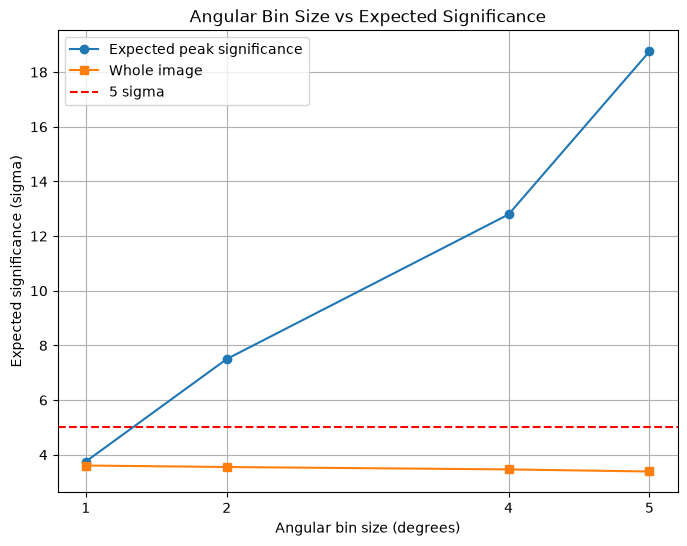

Largest peak: 18.75 sigma at 5 degrees
Whole image ranges from 3.39 to 3.61 sigma


In [6]:
steps = [1, 2, 4, 5]

S_peak = []
S_total = []

for step in steps:

    counts_void, ax_deg, ay_deg = sa.expected_counts(
        target0, detector, days=30, step_deg=step
    )

    counts_solid, _, _ = sa.expected_counts(
        target0.without_void(), detector, days=30, step_deg=step
    )

    S = mg.expected_significance(counts_void, counts_solid)
    peak = np.max(S)

    # compare the brightest bin with the same test using all the counts
    S_peak.append(peak)
    total = (counts_void.sum() - counts_solid.sum()) / np.sqrt(counts_solid.sum())
    S_total.append(total)

    print(f"Bin size: {step} degrees")
    print(f"Pixels: {S.size}")
    print(f"Peak: {peak:.3f} sigma, whole image: {total:.3f} sigma")
    print("--------------------------")

plt.figure(figsize=(8, 6))

plt.plot(steps, S_peak, marker="o", label="Expected peak significance")
plt.plot(steps, S_total, marker="s", label="Whole image")
plt.axhline(5, color="red", linestyle="--", label="5 sigma")

plt.xlabel("Angular bin size (degrees)")
plt.ylabel("Expected significance (sigma)")
plt.title("Angular Bin Size vs Expected Significance")

plt.xticks(steps)
plt.legend()
plt.grid(True)
plt.show()

peak_idx = np.argmax(S_peak)
print(f"Largest peak: {S_peak[peak_idx]:.2f} sigma at {steps[peak_idx]} degrees")
print(f"Whole image ranges from {min(S_total):.2f} to {max(S_total):.2f} sigma")

**Study D — Conclusion**

As the angular bin size increased from 1° to 5°, the expected peak significance also increased, from 3.75σ to 18.75σ.

This is because larger angular bins cover a greater solid angle, so our model predicts more muons per pixel, reducing relative statistical noise.

The 5° bins gave the highest peak, but the whole-image result stayed around 3.4–3.6σ. A bigger bin can raise the peak while making the image less detailed.

**Limitation:** Our model uses a single ray to represent each angular pixel rather than averaging over the entire angular bin. It also doesn't fully model the detector's angular resolution, so the results may overestimate the benefits of larger bins.

## Optional extension — a Malaysian target

Explore a Malaysian limestone hill or cave as a hypothetical target. Do not claim that no Malaysian muography survey exists unless you have independently verified that statement. The goal here is to build a plausible density model and estimate the exposure time that the same simulation pipeline would require.


Expected significance after 30 days: 9.09 sigma
Expected exposure for 5 sigma: 9.08 days


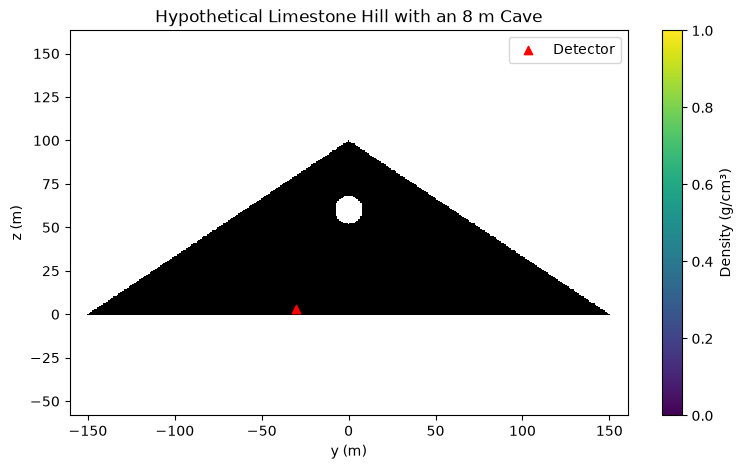

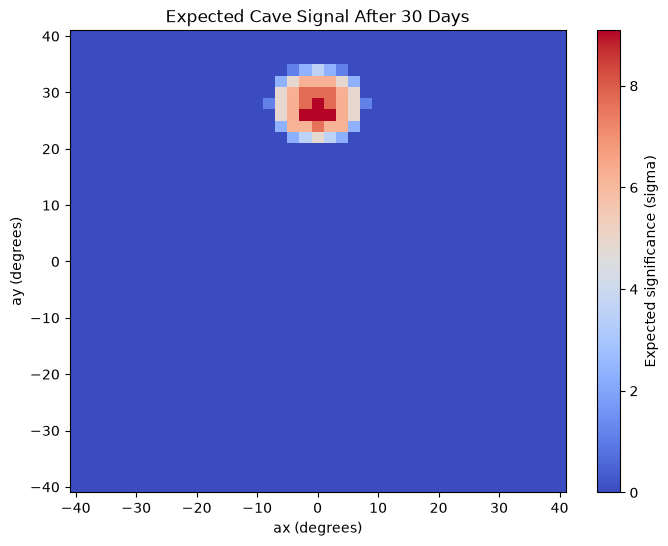

In [7]:
class LimestoneHill:
    # use a cone for the hill and a sphere for the cave
    def __init__(self, has_void=True):
        self.base_radius = 150.0
        self.height = 100.0
        self.void_centre = np.array([0.0, 0.0, 60.0])
        self.void_radius = 8.0
        self.has_void = has_void

    def density_at(self, x, y, z):
        radius_at_z = self.base_radius * (1 - np.clip(z, 0, self.height) / self.height)
        inside_hill = (z >= 0) & (z <= self.height) & (np.hypot(x, y) <= radius_at_z)
        density = np.where(inside_hill, cfg.ROCK_DENSITY_G_CM3, mg.RHO_AIR)
        if self.has_void:
            cx, cy, cz = self.void_centre
            distance_sq = (x - cx)**2 + (y - cy)**2 + (z - cz)**2
            density = np.where(distance_sq <= self.void_radius**2, mg.RHO_AIR, density)
        return density

    def without_void(self):
        return LimestoneHill(has_void=False)


hill = LimestoneHill()
hill_detector = np.array([0.0, -30.0, 3.0])
# use the same count pipeline for a completely different shape
counts_hill, ax_h, ay_h = sa.expected_counts(hill, hill_detector, days)
counts_hill0, _, _ = sa.expected_counts(hill.without_void(), hill_detector, days)
idx_hill = sa.signal_pixel(counts_hill, counts_hill0)
S_hill = mg.expected_significance(counts_hill, counts_hill0)
T5_hill = days * (5 / S_hill[idx_hill])**2
print(f"Expected significance after 30 days: {S_hill[idx_hill]:.2f} sigma")
print(f"Expected exposure for 5 sigma: {T5_hill:.2f} days")

y = np.linspace(-160, 160, 321)
z = np.linspace(0, 105, 211)
Y, Z = np.meshgrid(y, z)
density = hill.density_at(np.zeros_like(Y), Y, Z)

plt.figure(figsize=(9, 5))
plt.pcolormesh(Y, Z, density, shading="auto", cmap="gray_r")
plt.scatter(hill_detector[1], hill_detector[2], marker="^", color="red", label="Detector")
plt.xlabel("y (m)")
plt.ylabel("z (m)")
plt.title("Hypothetical Limestone Hill with an 8 m Cave")
plt.axis("equal")
plt.colorbar(label="Density (g/cm³)")
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))
plt.pcolormesh(ax_h, ay_h, S_hill, shading="auto", cmap="coolwarm")
plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Expected Cave Signal After 30 Days")
plt.colorbar(label="Expected significance (sigma)")
plt.show()

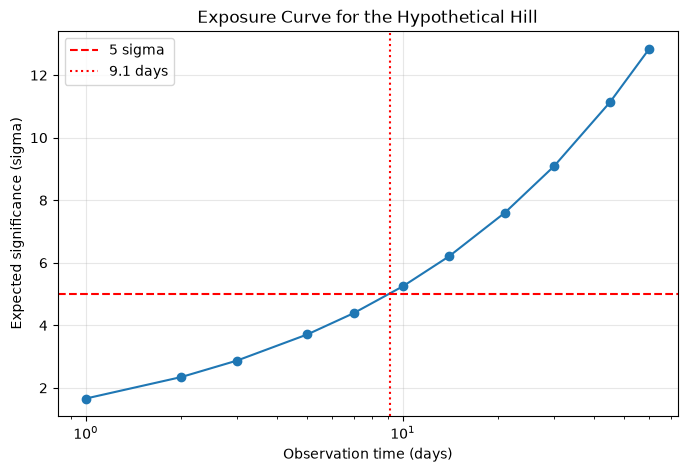

In [8]:
# turn the 30-day result into an exposure curve using the same sqrt rule
days_hill = np.array([1, 2, 3, 5, 7, 10, 14, 21, 30, 45, 60])
S_hill_curve = S_hill[idx_hill] * np.sqrt(days_hill / days)
plt.figure(figsize=(8, 5))
plt.plot(days_hill, S_hill_curve, marker="o")
plt.axhline(5, color="red", linestyle="--", label="5 sigma")
plt.axvline(T5_hill, color="red", linestyle=":", label=f"{T5_hill:.1f} days")
plt.xscale("log")
plt.xlabel("Observation time (days)")
plt.ylabel("Expected significance (sigma)")
plt.title("Exposure Curve for the Hypothetical Hill")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Extra check — what changes if the detector is bigger?

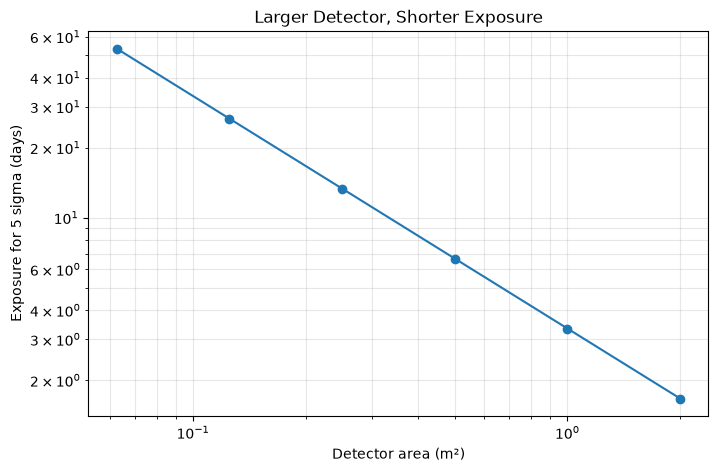

Log-log slope: -1.00


In [9]:
counts_base, ax_base, ay_base = sa.expected_counts(target0, detector, days)
counts_base0, _, _ = sa.expected_counts(target0.without_void(), detector, days)
idx_base = sa.signal_pixel(counts_base, counts_base0)
S_base = mg.expected_significance(counts_base, counts_base0)[idx_base]
t5_base = days * (5 / S_base)**2

# same rock, same ray. Only the number of muons we collect changes.
areas = np.array([0.0625, 0.125, 0.25, 0.5, 1, 2])
T5_area = []
for area in areas:
    scale = area / cfg.DETECTOR_AREA_M2
    S = mg.expected_significance(counts_base * scale, counts_base0 * scale)[idx_base]
    T5_area.append(days * (5 / S)**2)

plt.figure(figsize=(8, 5))
plt.loglog(areas, T5_area, marker="o")
plt.xlabel("Detector area (m²)")
plt.ylabel("Exposure for 5 sigma (days)")
plt.title("Larger Detector, Shorter Exposure")
plt.grid(alpha=0.3, which="both")
plt.show()
print(f"Log-log slope: {np.polyfit(np.log(areas), np.log(T5_area), 1)[0]:.2f}")

## Extra check — what if we assume the wrong rock density?

2.3 g/cm³: max -5.28σ, chosen pixel -7.91σ


2.4 g/cm³: max -2.52σ, chosen pixel -2.81σ


2.5 g/cm³: max 0.00σ, chosen pixel 0.00σ


2.6 g/cm³: max 9.46σ, chosen pixel 2.72σ


2.7 g/cm³: max 14.76σ, chosen pixel 5.36σ


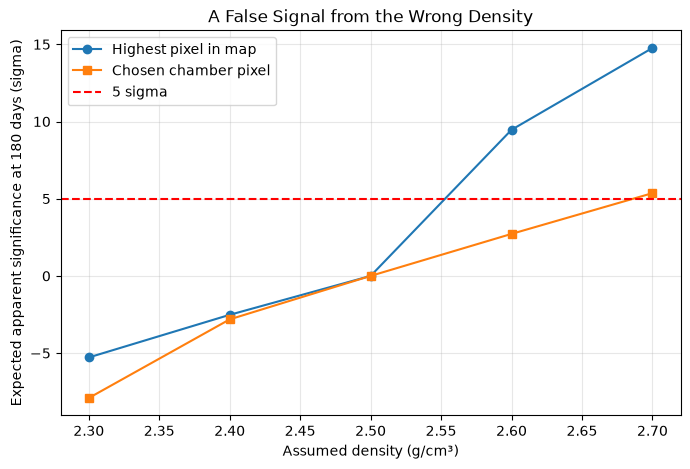

In [10]:
densities = np.array([2.3, 2.4, 2.5, 2.6, 2.7])
true_solid = make_target(has_void=False)
mu_true, _, _ = sa.expected_counts(true_solid, detector, 180.0)
S_max = []
S_at_signal = []

for density in densities:
    # there's no cave in either target. The only change is the assumed density.
    reference = make_target(density=density, has_void=False)
    mu_ref, _, _ = sa.expected_counts(reference, detector, 180.0)
    S = mg.expected_significance(mu_true, mu_ref)
    S_max.append(S.max())
    S_at_signal.append(S[idx_base])
    print(f"{density:.1f} g/cm³: max {S.max():.2f}σ, chosen pixel {S[idx_base]:.2f}σ")

plt.figure(figsize=(8, 5))
plt.plot(densities, S_max, marker="o", label="Highest pixel in map")
plt.plot(densities, S_at_signal, marker="s", label="Chosen chamber pixel")
plt.axhline(5, color="red", linestyle="--", label="5 sigma")
plt.xlabel("Assumed density (g/cm³)")
plt.ylabel("Expected apparent significance at 180 days (sigma)")
plt.title("A False Signal from the Wrong Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Extra check — one pixel versus all the counts

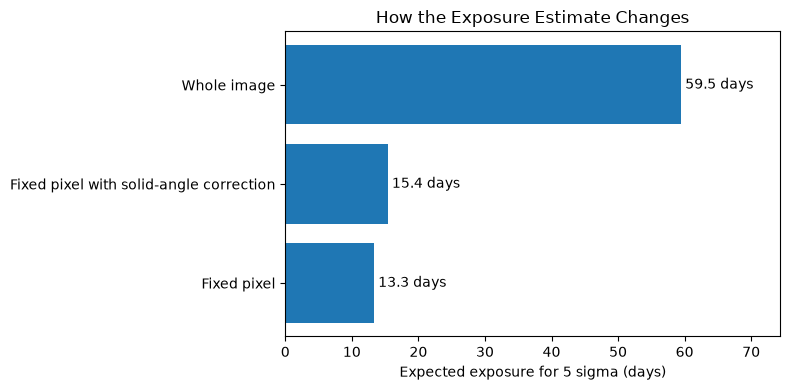

Fixed pixel: 13.33 days
Fixed pixel with solid-angle correction: 15.39 days
Whole image: 59.46 days


In [11]:
# add counts before dividing by the noise for the whole-image statistic
S_whole = (counts_base.sum() - counts_base0.sum()) / np.sqrt(counts_base0.sum())
t5_whole = days * (5 / S_whole)**2
factor = sa.solid_angle_factor(ax_base, ay_base)
S_corrected = mg.expected_significance(counts_base * factor, counts_base0 * factor)[idx_base]
t5_corrected = days * (5 / S_corrected)**2

labels = ["Fixed pixel", "Fixed pixel with solid-angle correction", "Whole image"]
exposures = [t5_base, t5_corrected, t5_whole]
plt.figure(figsize=(8, 4))
bars = plt.barh(labels, exposures)
plt.bar_label(bars, fmt="%.1f days", padding=3)
plt.xlim(0, max(exposures) * 1.25)
plt.xlabel("Expected exposure for 5 sigma (days)")
plt.title("How the Exposure Estimate Changes")
plt.tight_layout()
plt.show()

for label, exposure in zip(labels, exposures):
    print(f"{label}: {exposure:.2f} days")

## Before demo day

Restart each notebook separately and use **Kernel → Restart & Run All**. The notebooks should not require you to run another notebook first. In particular, notebooks 03–05 should import the shared functions from `code/student_analysis.py`.
